In [6]:
from sklearn.datasets import fetch_20newsgroups

categories = [
    "sci.med",
    "rec.autos",
    "talk.politics.mideast",
    "comp.graphics",
]

newsgroups = fetch_20newsgroups(
    subset="all",
    categories=categories,
    shuffle=True,
    random_state=42,
    remove=("headers", "footers", "quotes")
)

print("Numar total de documente: ", len(newsgroups.data))
print("Categoriile disponibile: ", newsgroups.target_names)


for category, category_id in zip(newsgroups.target_names, range(len(newsgroups.target_names))):
    count = sum(newsgroups.target == category_id)
    print(f"{category}: {count} documente")

Numar total de documente:  3893
Categoriile disponibile:  ['comp.graphics', 'rec.autos', 'sci.med', 'talk.politics.mideast']
comp.graphics: 973 documente
rec.autos: 990 documente
sci.med: 990 documente
talk.politics.mideast: 940 documente


In [7]:
for document_index in range(3):
    document = newsgroups.data[document_index]
    category = newsgroups.target_names[newsgroups.target[document_index]]

    non_empty_lines = [
        line for line in document.splitlines()
        if line.strip()
    ]

    print(f"\nDOCUMENTUL {document_index + 1}")
    print("Categoria:", category)
    print("-" * 80)
    print("\n".join(non_empty_lines[:10]))


DOCUMENTUL 1
Categoria: comp.graphics
--------------------------------------------------------------------------------
[edited]
Well for starters, why use rle files?  You might have a specific program that
needs them, OK, but I tend to convert straight to jpeg format, thus a 2.4meg
24bit targa file becomes a ~80k or less 24bit jpeg.
The latest versions of XV (2.2.1 ?) and xloadimage (3.03) both handle jpeg files.
And the best way to convert to jpeg is with the c/djpeg suit.  Even at 90%
quality (you can't see the difference) the jpeg is way smaller than anything
else even an 8bit gif!
Later'ish
Craig

DOCUMENTUL 2
Categoria: rec.autos
--------------------------------------------------------------------------------
Talking about car alarms, there are certain cars in this country that are 
only insurable if they are fitted with a Vecta alarm. We're talking Coswoths
and Porsches and stuff. Just before they (the insurance companies) decided to 
make this move, they insisted that the car b

In [8]:
import re
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

In [9]:
def clean_text(text):
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

cleaned_documents = [
    clean_text(doc) for doc in newsgroups.data
]

print("Inainte de curatare:")
print(newsgroups.data[0][:500])

print("\nDupa curatare:")
print(cleaned_documents[0][:500])

Inainte de curatare:

[edited]



Well for starters, why use rle files?  You might have a specific program that
needs them, OK, but I tend to convert straight to jpeg format, thus a 2.4meg
24bit targa file becomes a ~80k or less 24bit jpeg.

The latest versions of XV (2.2.1 ?) and xloadimage (3.03) both handle jpeg files.
And the best way to convert to jpeg is with the c/djpeg suit.  Even at 90%
quality (you can't see the difference) the jpeg is way smaller than anything
else even an 8bit gif!

Later'ish
Craig

Dupa curatare:
[edited] Well for starters, why use rle files? You might have a specific program that needs them, OK, but I tend to convert straight to jpeg format, thus a 2.4meg 24bit targa file becomes a ~80k or less 24bit jpeg. The latest versions of XV (2.2.1 ?) and xloadimage (3.03) both handle jpeg files. And the best way to convert to jpeg is with the c/djpeg suit. Even at 90% quality (you can't see the difference) the jpeg is way smaller than anything else even an 8bit gi

In [10]:
stop_words = set(STOPWORDS)

print(stop_words)

{'some', "aren't", 'www', 'doing', 'your', 'own', 'yours', 'as', 'nor', "weren't", "how's", "here's", 'my', 'such', 'down', "doesn't", 'com', 'are', 'these', "you've", "it's", "hasn't", 'until', 'theirs', 'too', 'by', 'from', 'off', 'herself', 'http', 'at', 'just', 'otherwise', "she's", 'hence', "shouldn't", "they'll", "i'd", 'during', 'whom', 'then', 'her', 'me', 'could', 'over', "let's", 'against', 'to', 'like', 'which', 'else', "what's", 'shall', 'yourself', 'k', "they're", "i'm", "we'll", 'who', 'itself', "she'd", "he'll", "when's", 'am', 'their', "you're", 'each', 'ourselves', "mustn't", 'into', 'also', "hadn't", 'ever', 'on', 'should', 'under', 'cannot', 'between', 'while', "i've", "they've", 'both', 'has', 'she', "he's", 'any', 'up', "didn't", 'here', 'been', 'our', 'all', 'when', 'more', 'therefore', 'through', 'ought', "where's", 'you', "shan't", 'where', 'not', 'few', 'would', 'is', 'so', 'did', "won't", 'r', "don't", "isn't", 'they', 'does', 'was', 'it', 'most', 'before', 'b

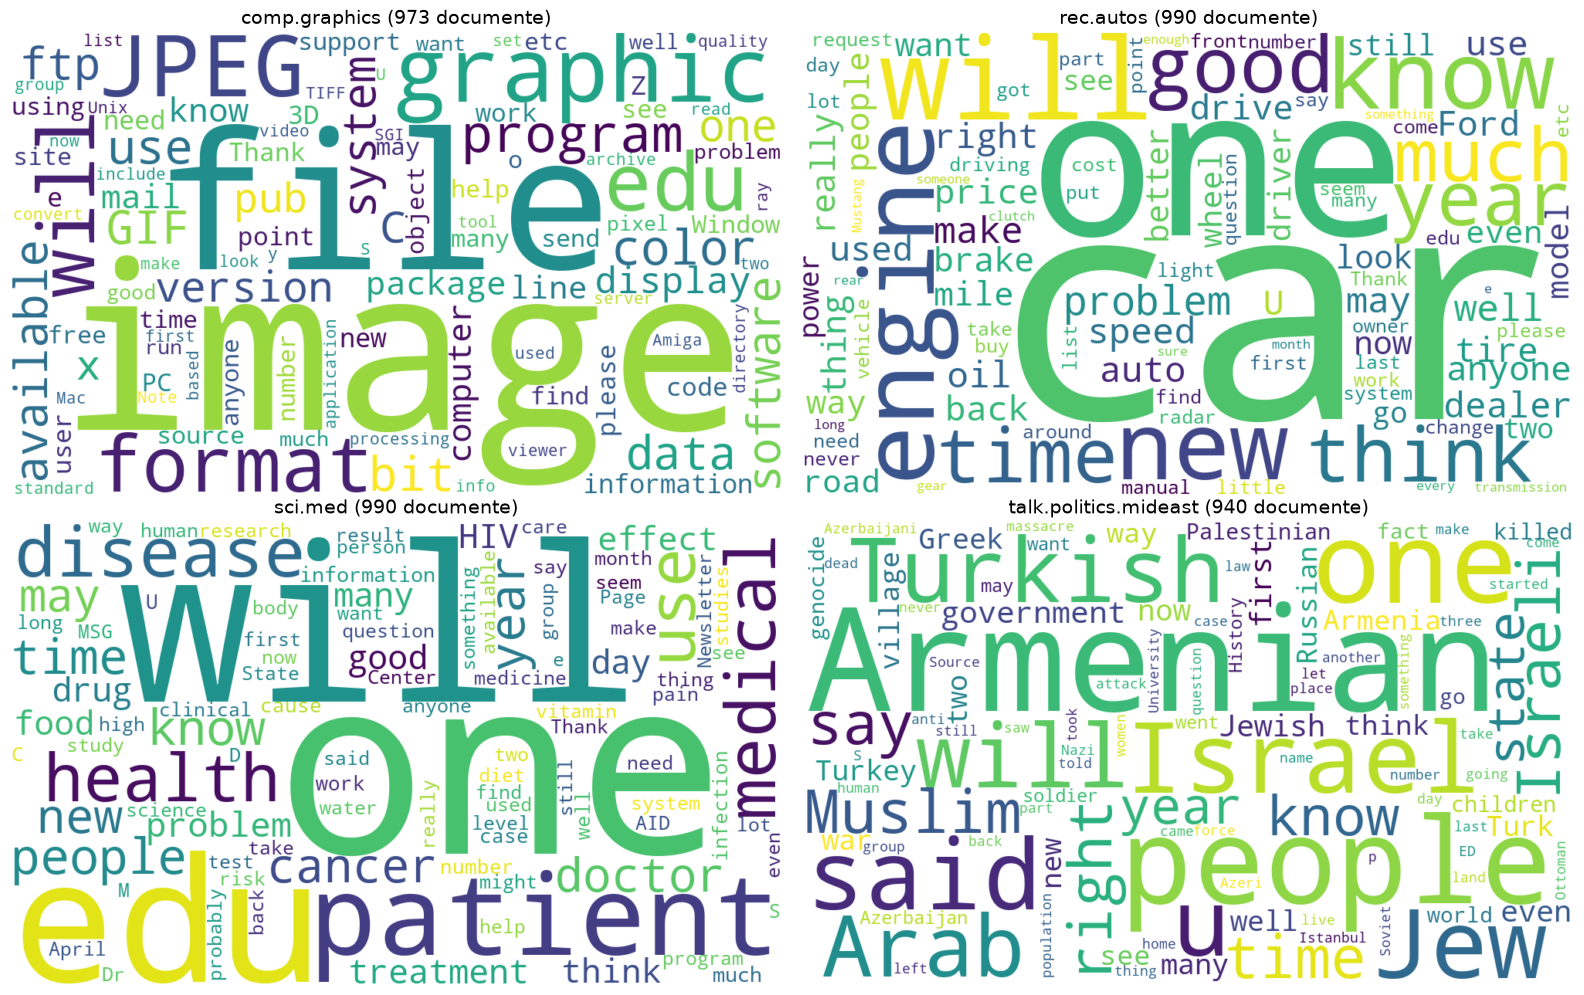

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for category_id, category_name in enumerate(newsgroups.target_names):

    category_documents = [
        cleaned_documents[index]
        for index, target in enumerate(newsgroups.target)
        if target == category_id
    ]

    category_text = " ".join(category_documents)

    wordcloud = WordCloud(
        width=1000,
        height=600,
        background_color="white",
        stopwords=stop_words,
        collocations=False,
        max_words=100
    ).generate(category_text)

    axes[category_id].imshow(wordcloud, interpolation="bilinear")
    axes[category_id].set_title(
        f"{category_name} ({len(category_documents)} documente)",
        fontsize=14
    )
    axes[category_id].axis("off")

plt.tight_layout()
plt.savefig("wordcloud_categories.png", dpi=300, bbox_inches="tight")
plt.show()

In [1]:
from collections import Counter

import pandas as pd
import spacy

spacy.require_gpu()

nlp = spacy.load("en_core_web_sm")

print("Modelul spaCy a fost incarcat pe GPU.")

c:\Users\iana.denis\Desktop\NLP\.venv\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


Modelul spaCy a fost incarcat pe GPU.


In [2]:
def get_dependency_depth(token):
    depth = 0
    current_token = token

    while current_token.head != current_token:
        depth += 1
        current_token = current_token.head

    return depth

In [12]:
def compute_features(doc):
    # Păstrăm numai cuvintele alfabetice.
    # Eliminăm punctuația, spațiile și numerele izolate.
    words = [
        token
        for token in doc
        if token.is_alpha
    ]

    # Păstrăm numai propozițiile care conțin cel puțin un cuvânt.
    sentences = [
        sentence
        for sentence in doc.sents
        if any(token.is_alpha for token in sentence)
    ]

    word_count = len(words)
    sentence_count = len(sentences)

    # Unele documente pot fi goale după curățare.
    if word_count == 0 or sentence_count == 0:
        return {
            "word_count": word_count,
            "sentence_count": sentence_count,
            "ttr": 0.0,
            "words_per_sentence": 0.0,
            "nouns_per_sentence": 0.0,
            "avg_dependency_depth": 0.0,
            "avg_word_length": 0.0,
            "named_entity_density": 0.0,
            "lexical_density": 0.0,
            "hapax_ratio": 0.0,
        }

    # Formele cuvintelor scrise cu litere mici.
    # Astfel, "Car" și "car" sunt același tip.
    normalized_words = [
        token.text.lower()
        for token in words
    ]

    # 1. Type-Token Ratio
    unique_words = set(normalized_words)
    ttr = len(unique_words) / word_count

    # 2. Numărul mediu de cuvinte pe propoziție
    words_per_sentence = word_count / sentence_count

    # 3. Numărul mediu de substantive pe propoziție
    nouns = [
        token
        for token in words
        if token.pos_ in {"NOUN", "PROPN"}
    ]

    nouns_per_sentence = len(nouns) / sentence_count

    # 4. Distanța medie a cuvintelor față de rădăcină
    dependency_depths = [
        get_dependency_depth(token)
        for token in words
    ]

    avg_dependency_depth = (
        sum(dependency_depths) / len(dependency_depths)
    )

    # 5. Lungimea medie a cuvintelor
    avg_word_length = (
        sum(len(token.text) for token in words)
        / word_count
    )

    # 6. Proporția cuvintelor care fac parte din entități
    entity_words = [
        token
        for token in words
        if token.ent_iob_ != "O"
    ]

    named_entity_density = len(entity_words) / word_count

    # 7. Densitatea lexicală:
    # substantive + verbe + adjective + adverbe
    lexical_words = [
        token
        for token in words
        if token.pos_ in {
            "NOUN",
            "PROPN",
            "VERB",
            "ADJ",
            "ADV",
        }
    ]

    lexical_density = len(lexical_words) / word_count

    # 8. Hapax ratio:
    # proporția cuvintelor care apar o singură dată
    word_frequencies = Counter(normalized_words)

    hapax_words = [
        word
        for word, frequency in word_frequencies.items()
        if frequency == 1
    ]

    hapax_ratio = len(hapax_words) / word_count

    return {
        "word_count": word_count,
        "sentence_count": sentence_count,
        "ttr": ttr,
        "words_per_sentence": words_per_sentence,
        "nouns_per_sentence": nouns_per_sentence,
        "avg_dependency_depth": avg_dependency_depth,
        "avg_word_length": avg_word_length,
        "named_entity_density": named_entity_density,
        "lexical_density": lexical_density,
        "hapax_ratio": hapax_ratio,
    }

In [13]:
feature_rows = []

processed_documents = nlp.pipe(
    cleaned_documents,
    batch_size=64
)

total_documents = len(cleaned_documents)

for document_index, doc in enumerate(processed_documents):
    features = compute_features(doc)

    category_id = int(newsgroups.target[document_index])
    category_name = newsgroups.target_names[category_id]

    features["document_id"] = document_index
    features["category_id"] = category_id
    features["category"] = category_name

    feature_rows.append(features)

    if (document_index + 1) % 250 == 0:
        print(
            f"Procesate {document_index + 1} "
            f"din {total_documents} documente"
        )

print(f"Procesare terminată: {len(feature_rows)} documente.")

Procesate 250 din 3893 documente
Procesate 500 din 3893 documente
Procesate 750 din 3893 documente
Procesate 1000 din 3893 documente
Procesate 1250 din 3893 documente
Procesate 1500 din 3893 documente
Procesate 1750 din 3893 documente
Procesate 2000 din 3893 documente
Procesate 2250 din 3893 documente
Procesate 2500 din 3893 documente
Procesate 2750 din 3893 documente
Procesate 3000 din 3893 documente
Procesate 3250 din 3893 documente
Procesate 3500 din 3893 documente
Procesate 3750 din 3893 documente
Procesare terminată: 3893 documente.


In [17]:
features_df = pd.DataFrame(feature_rows)

column_order = [
    "document_id",
    "category_id",
    "category",
    "word_count",
    "sentence_count",
    "ttr",
    "words_per_sentence",
    "nouns_per_sentence",
    "avg_dependency_depth",
    "avg_word_length",
    "named_entity_density",
    "lexical_density",
    "hapax_ratio",
]

features_df = features_df[column_order]


print("\nPRIMELE 5 DOCUMENTE PROCESATE")
print("=" * 120)
print(features_df.head().to_string(index=False))


# Explicațiile coloanelor
column_explanations = {
    "document_id": (
        "Identificatorul documentului, adică poziția sa în dataset."
    ),

    "category_id": (
        "Eticheta numerică a categoriei documentului."
    ),

    "category": (
        "Numele categoriei din care face parte documentul."
    ),

    "word_count": (
        "Numărul total de cuvinte alfabetice din document. "
        "Punctuația, spațiile și numerele izolate nu sunt numărate."
    ),

    "sentence_count": (
        "Numărul propozițiilor identificate de modelul spaCy."
    ),

    "ttr": (
        "Type-Token Ratio = numărul cuvintelor distincte / "
        "numărul total de cuvinte. Valoarea este între 0 și 1. "
        "O valoare mai mare indică un vocabular mai variat."
    ),

    "words_per_sentence": (
        "Numărul total de cuvinte / numărul propozițiilor. "
        "Arată lungimea medie a unei propoziții."
    ),

    "nouns_per_sentence": (
        "Numărul substantivelor comune și proprii / "
        "numărul propozițiilor. Arată câte substantive sunt folosite, "
        "în medie, într-o propoziție."
    ),

    "avg_dependency_depth": (
        "Distanța sintactică medie a cuvintelor față de rădăcina "
        "propoziției. O valoare mai mare poate indica propoziții cu "
        "o structură sintactică mai complexă."
    ),

    "avg_word_length": (
        "Numărul total de caractere din cuvinte / numărul cuvintelor. "
        "Arată lungimea medie a unui cuvânt."
    ),

    "named_entity_density": (
        "Numărul cuvintelor care fac parte din entități numite / "
        "numărul total de cuvinte. Entitățile pot fi persoane, "
        "organizații, țări, localități sau date. Valoarea este "
        "între 0 și 1."
    ),

    "lexical_density": (
        "Numărul substantivelor, verbelor, adjectivelor și adverbelor / "
        "numărul total de cuvinte. Arată cât de mult conținut lexical "
        "există în text. Valoarea este între 0 și 1."
    ),

    "hapax_ratio": (
        "Numărul cuvintelor care apar exact o singură dată / "
        "numărul total de cuvinte. O valoare mai mare poate indica "
        "un vocabular mai divers."
    ),
}


print("\n\nEXPLICAȚIA COLOANELOR")
print("=" * 120)

for column_name in column_order:
    print(f"\n{column_name}")
    print("-" * len(column_name))
    print(column_explanations[column_name])


PRIMELE 5 DOCUMENTE PROCESATE
 document_id  category_id      category  word_count  sentence_count      ttr  words_per_sentence  nouns_per_sentence  avg_dependency_depth  avg_word_length  named_entity_density  lexical_density  hapax_ratio
           0            0 comp.graphics          81               6 0.753086           13.500000                4.00              2.629630         4.074074              0.024691         0.555556     0.617284
           1            1     rec.autos          77               4 0.675325           19.250000                5.25              2.779221         4.688312              0.090909         0.532468     0.480519
           2            2       sci.med          71               4 0.760563           17.750000                4.75              2.718310         4.633803              0.000000         0.535211     0.605634
           3            2       sci.med          22               3 0.863636            7.333333                3.00              1.63636

In [15]:
feature_columns = [
    "word_count",
    "sentence_count",
    "ttr",
    "words_per_sentence",
    "nouns_per_sentence",
    "avg_dependency_depth",
    "avg_word_length",
    "named_entity_density",
    "lexical_density",
    "hapax_ratio",
]

category_summary = (
    features_df
    .groupby("category")[feature_columns]
    .mean()
    .round(3)
)

print(category_summary)

                       word_count  sentence_count    ttr  words_per_sentence  \
category                                                                       
comp.graphics             183.313          13.023  0.743              13.556   
rec.autos                 108.671           7.497  0.715              13.202   
sci.med                   192.417          11.730  0.700              14.993   
talk.politics.mideast     344.491          21.490  0.656              15.549   

                       nouns_per_sentence  avg_dependency_depth  \
category                                                          
comp.graphics                       4.317                 2.531   
rec.autos                           3.533                 2.340   
sci.med                             3.962                 2.622   
talk.politics.mideast               4.335                 2.747   

                       avg_word_length  named_entity_density  lexical_density  \
category                           

In [16]:
features_df.to_csv(
    "document_features.csv",
    index=False
)

category_summary.to_csv(
    "category_feature_summary.csv"
)

print("Rezultatele au fost salvate.")

Rezultatele au fost salvate.


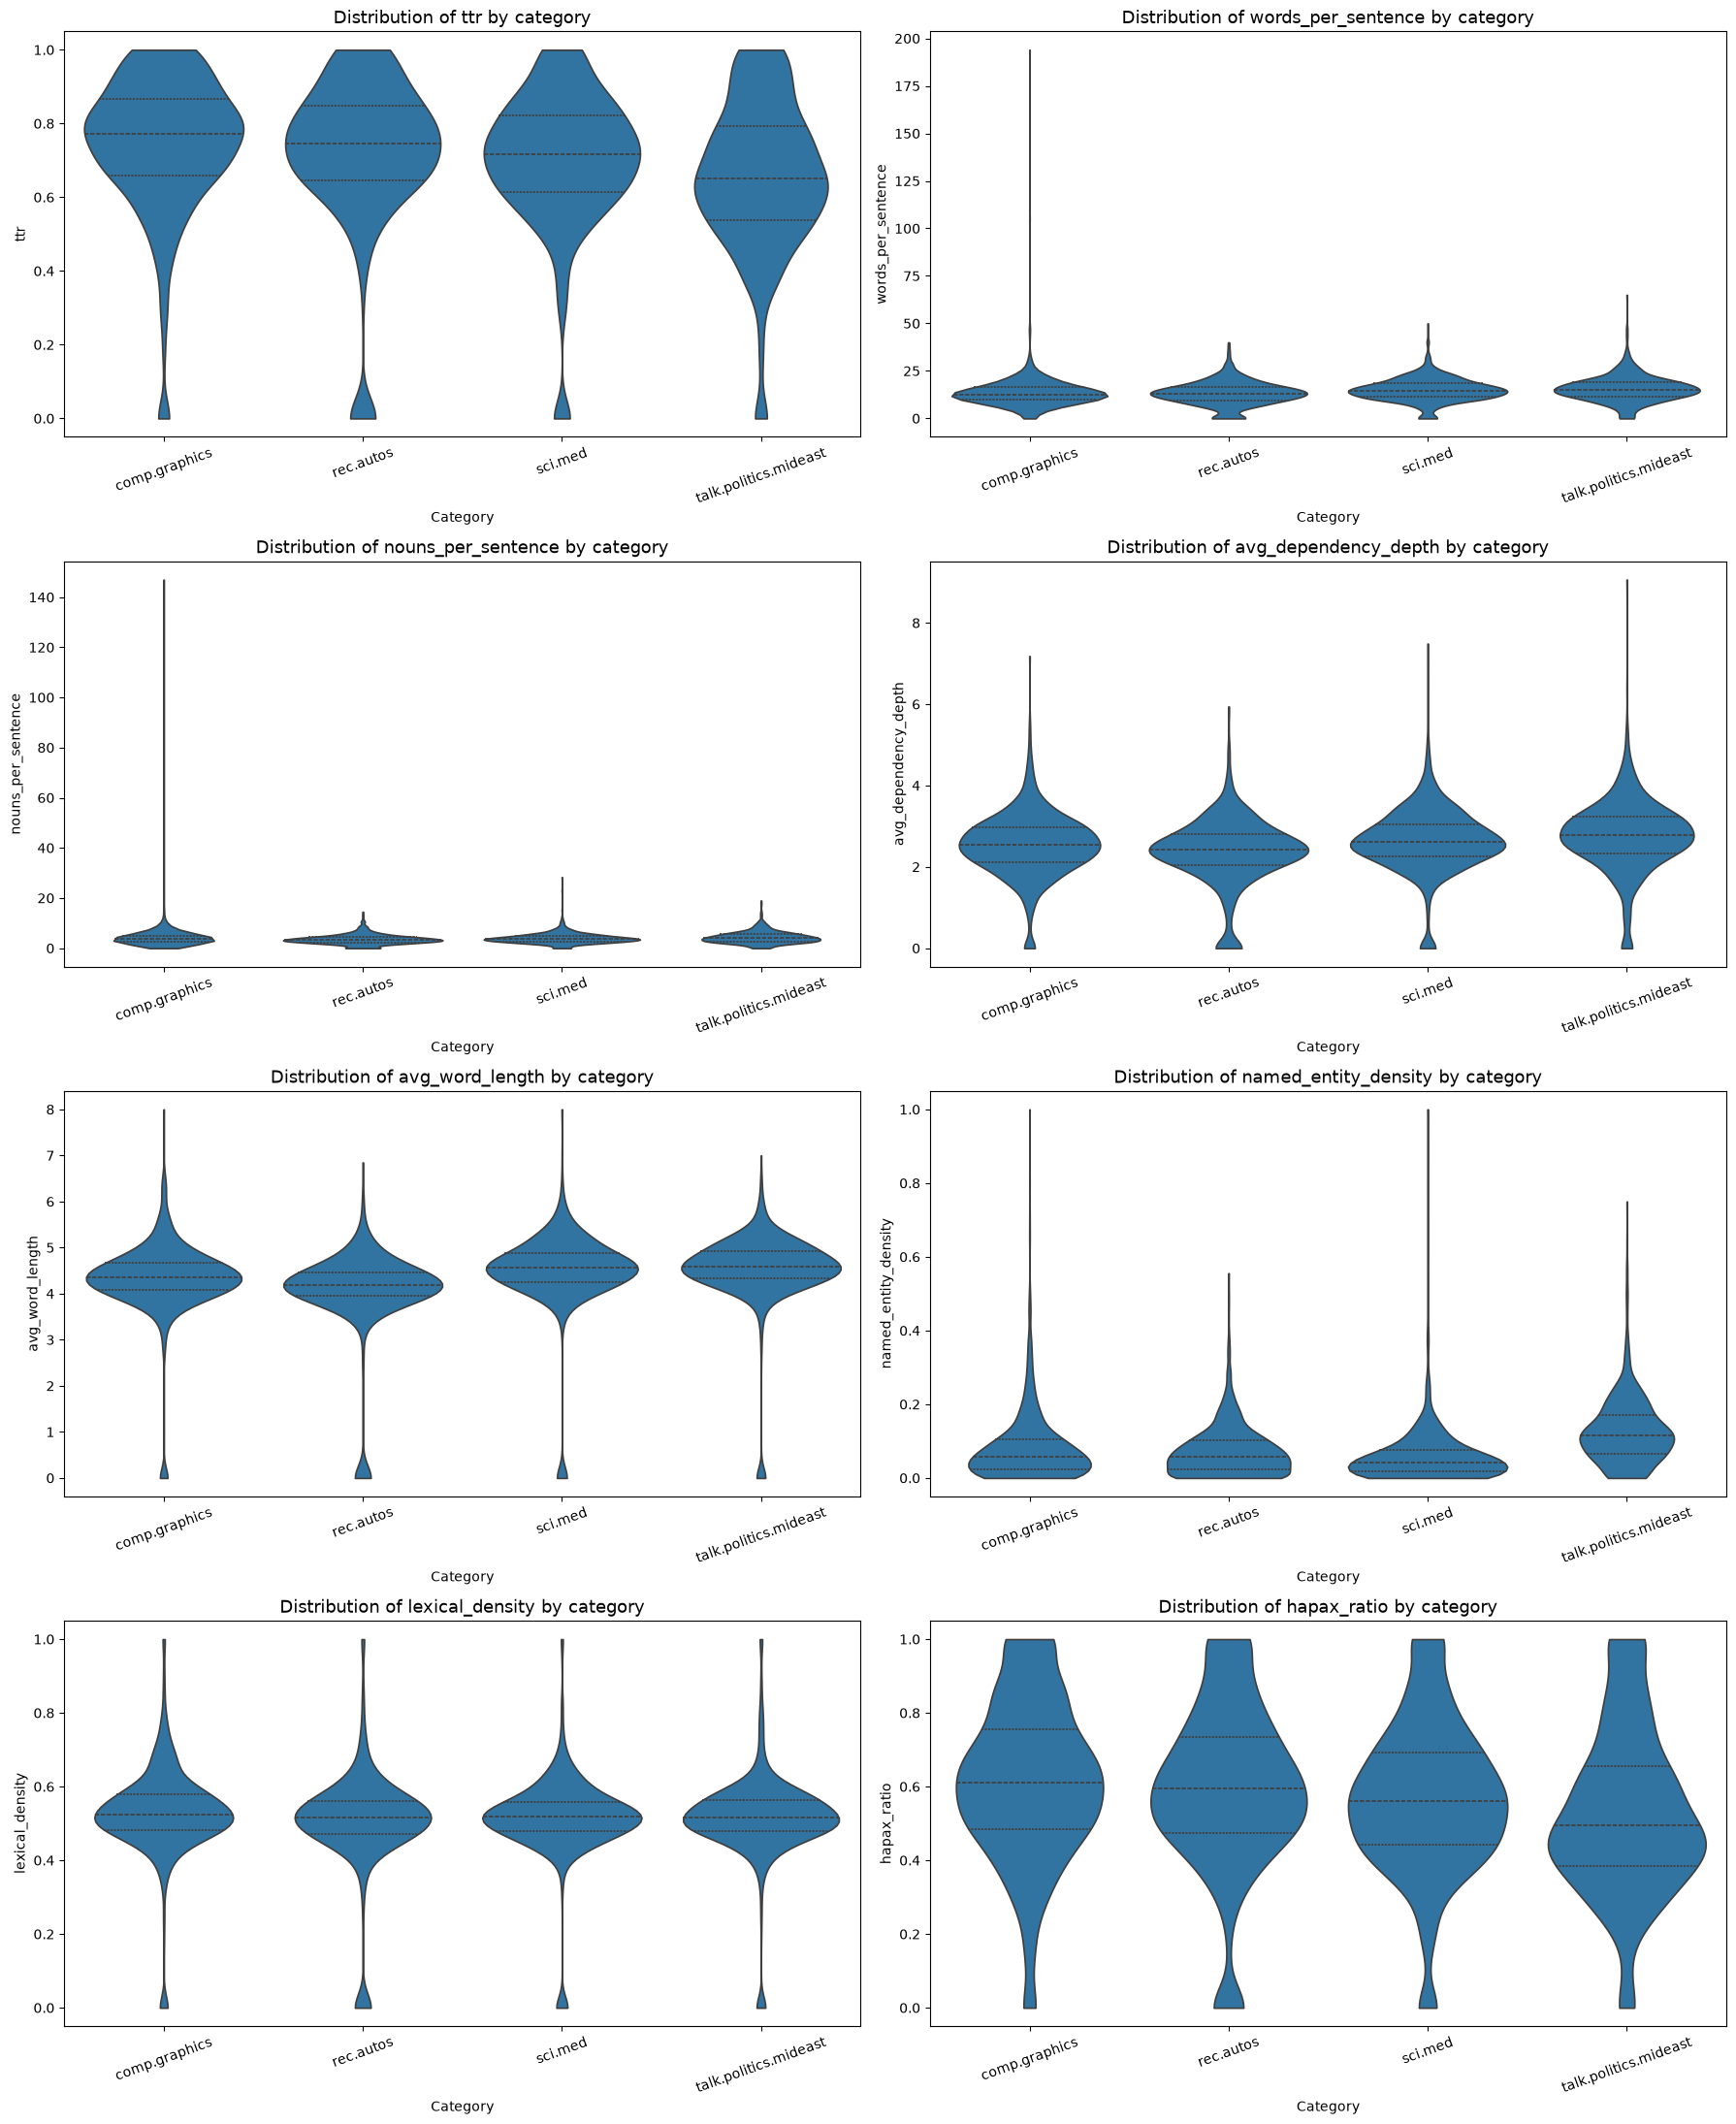

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns


features_to_plot = [
    "ttr",
    "words_per_sentence",
    "nouns_per_sentence",
    "avg_dependency_depth",
    "avg_word_length",
    "named_entity_density",
    "lexical_density",
    "hapax_ratio",
]

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(18, 22)
)

axes = axes.flatten()

for feature, ax in zip(features_to_plot, axes):
    sns.violinplot(
        data=features_df,
        x="category",
        y=feature,
        inner="quartile",
        cut=0,
        ax=ax
    )

    ax.set_title(
        f"Distribution of {feature} by category",
        fontsize=13
    )

    ax.set_xlabel("Category")
    ax.set_ylabel(feature)

    ax.tick_params(
        axis="x",
        rotation=20
    )

plt.tight_layout()

plt.savefig(
    "feature_distributions_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

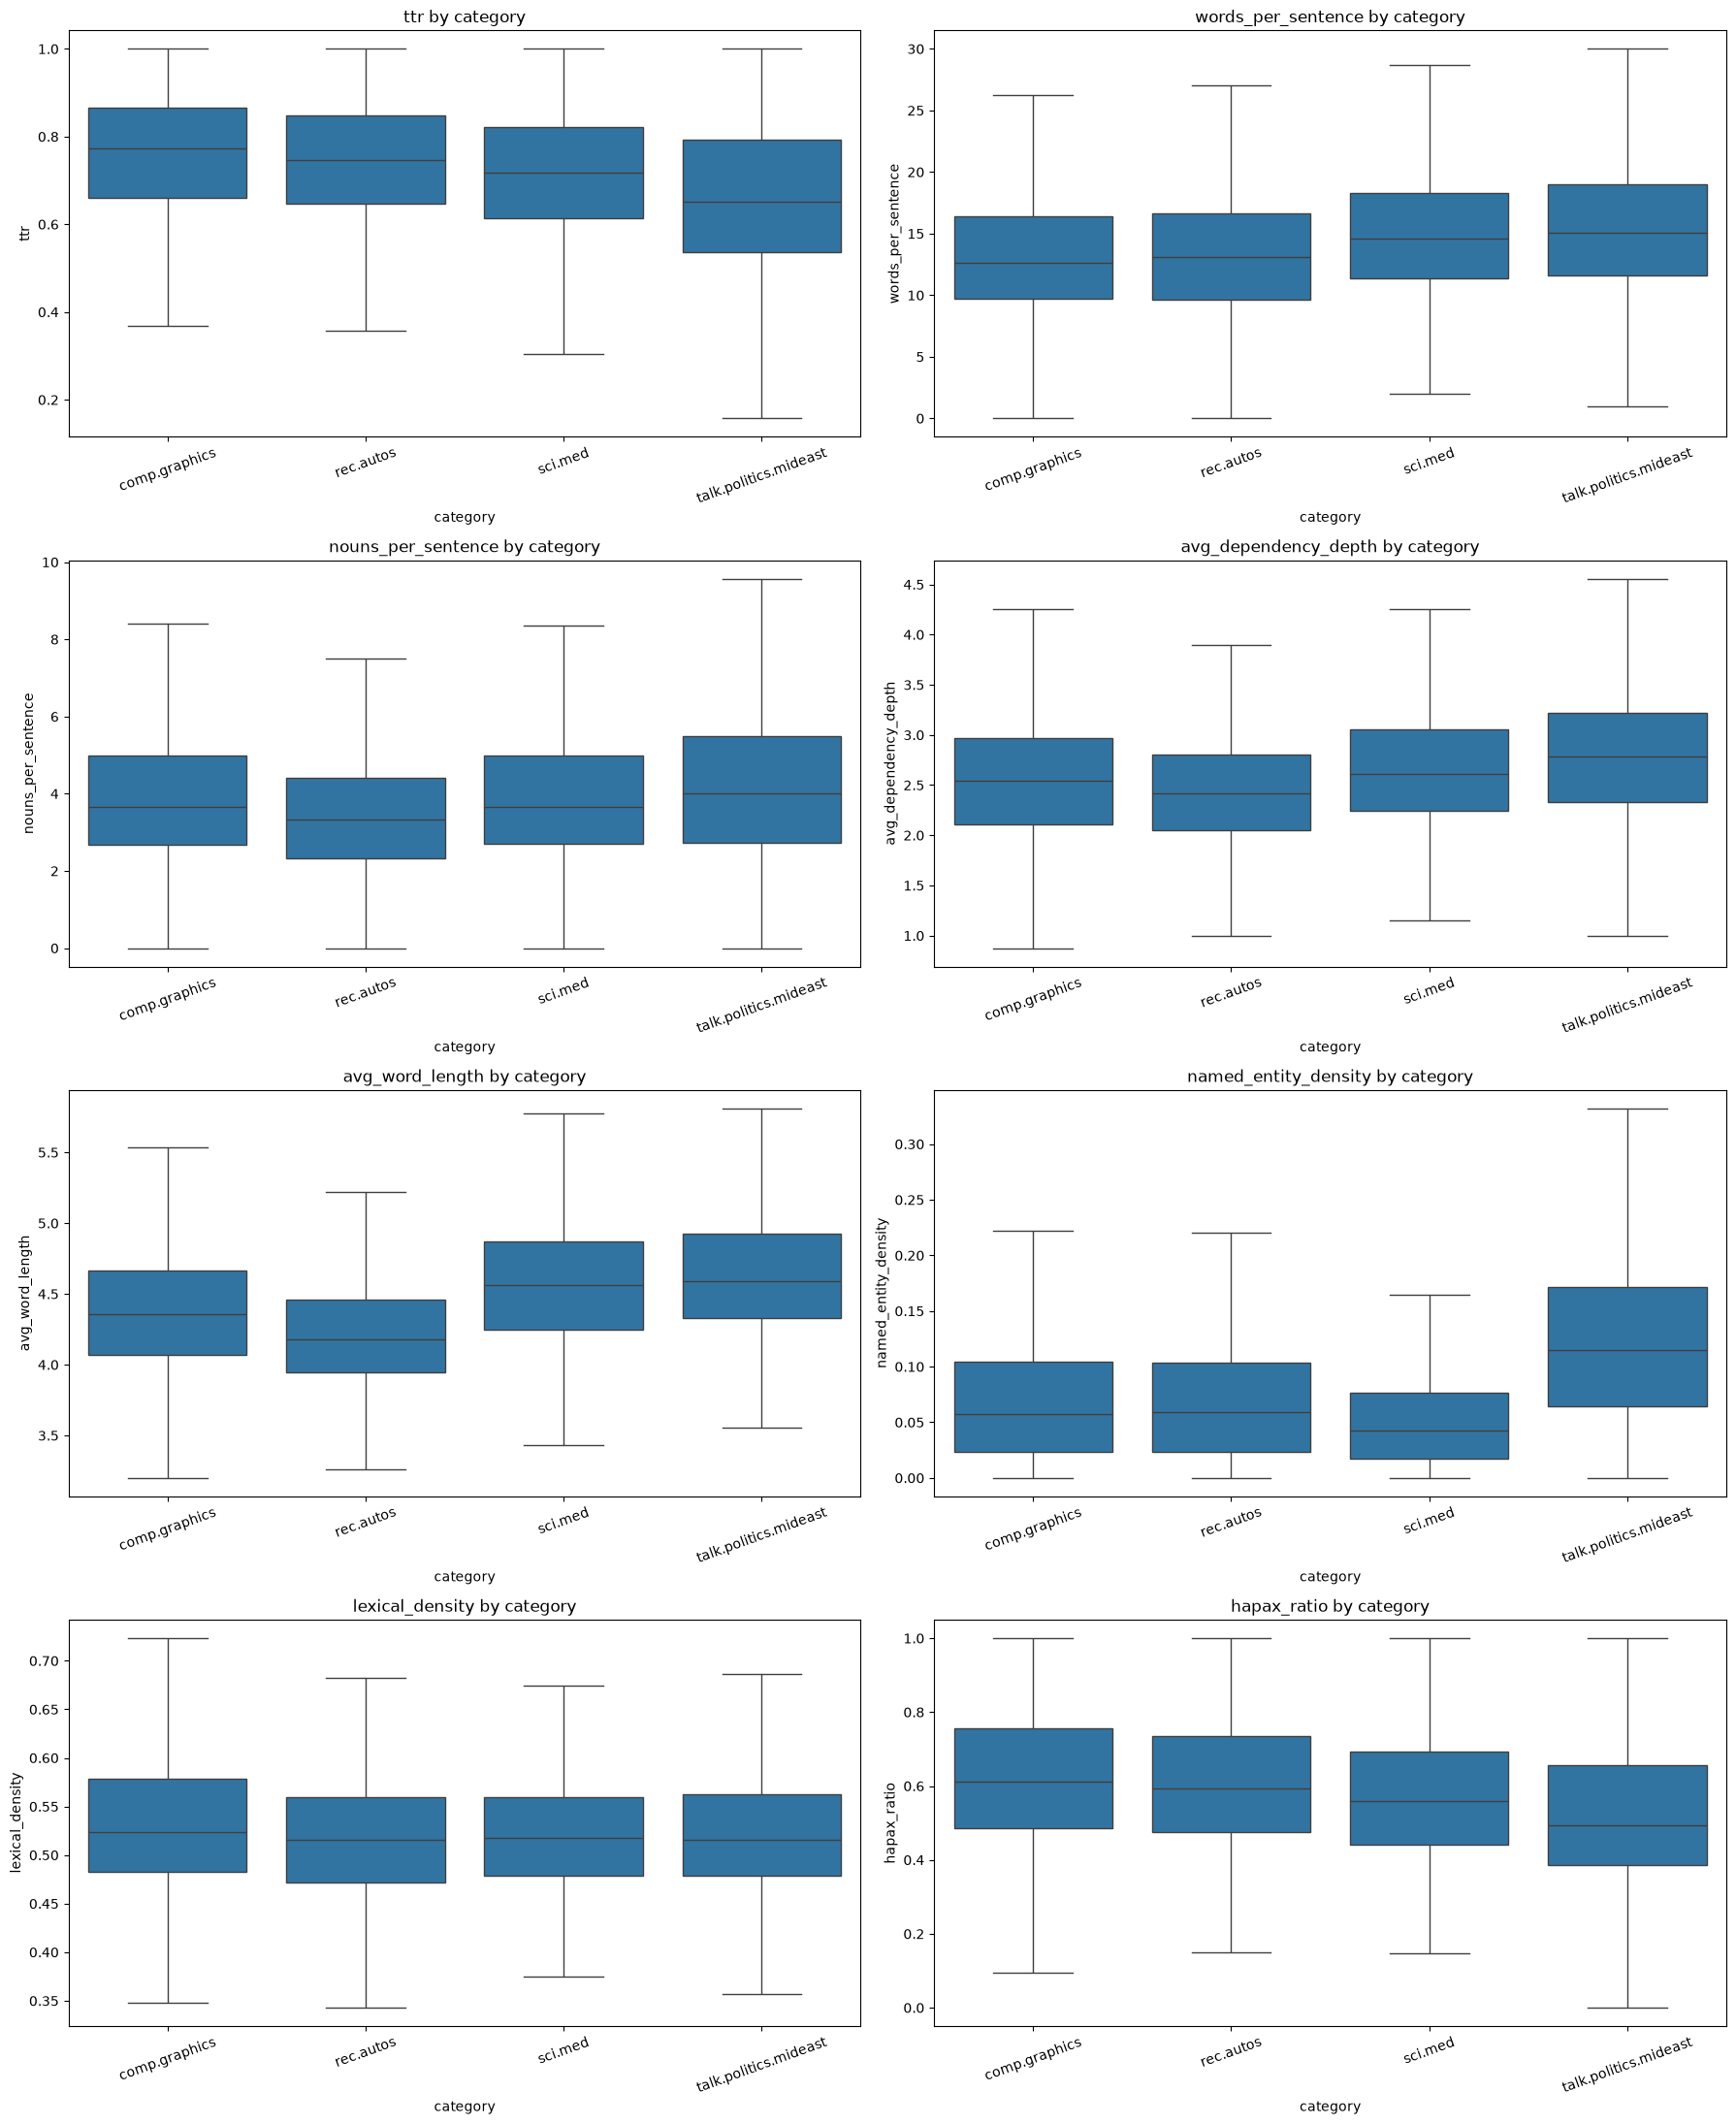

In [20]:
fig, axes = plt.subplots(4, 2, figsize=(18, 22))
axes = axes.flatten()

for feature, ax in zip(features_to_plot, axes):
    sns.boxplot(
        data=features_df,
        x="category",
        y=feature,
        showfliers=False,
        ax=ax
    )

    ax.set_title(f"{feature} by category")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(
    "feature_boxplots_by_category.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [21]:
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix, hstack
from gensim.models import Word2Vec

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

SEED = 42

In [22]:
feature_columns = [
    "word_count",
    "sentence_count",
    "ttr",
    "words_per_sentence",
    "nouns_per_sentence",
    "avg_dependency_depth",
    "avg_word_length",
    "named_entity_density",
    "lexical_density",
    "hapax_ratio",
]

data = features_df.copy()

data["text"] = [
    cleaned_documents[int(document_id)]
    for document_id in data["document_id"]
]

initial_count = len(data)

data = data.loc[
    (data["word_count"] > 0)
    & data["text"].str.strip().ne("")
].copy()

data = data.drop_duplicates(subset="text").reset_index(drop=True)

print(f"Documente păstrate: {len(data)} / {initial_count}")

texts = data["text"].to_numpy()
y = data["category"].to_numpy()
X_style = data[feature_columns].to_numpy(dtype=np.float64)

assert np.isfinite(X_style).all(), "Există valori lipsă sau infinite."

train_idx, test_idx = train_test_split(
    np.arange(len(data)),
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

texts_train = texts[train_idx]
texts_test = texts[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

X_style_train = X_style[train_idx]
X_style_test = X_style[test_idx]

print("Train:", len(train_idx))
print("Test:", len(test_idx))

print(
    pd.DataFrame({
        "Train": pd.Series(y_train).value_counts(),
        "Test": pd.Series(y_test).value_counts(),
    })
)

# Salvăm împărțirea pentru a putea reproduce experimentul.
data["split"] = "train"
data.loc[test_idx, "split"] = "test"

data[["document_id", "category", "split"]].to_csv(
    "classification_split.csv",
    index=False,
)

Documente păstrate: 3756 / 3893
Train: 3004
Test: 752
                       Train  Test
sci.med                  765   191
comp.graphics            761   191
rec.autos                747   187
talk.politics.mideast    731   183


In [23]:
style_scaler = StandardScaler()

X_style_train_scaled = style_scaler.fit_transform(X_style_train)
X_style_test_scaled = style_scaler.transform(X_style_test)

print("Stilometrie train:", X_style_train_scaled.shape)
print("Stilometrie test:", X_style_test_scaled.shape)

Stilometrie train: (3004, 10)
Stilometrie test: (752, 10)


In [24]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 1),
    min_df=2,
    max_df=0.95,
    max_features=10_000,
    sublinear_tf=True,
    norm="l2",
    dtype=np.float32,
)

X_tfidf_train = tfidf.fit_transform(texts_train)
X_tfidf_test = tfidf.transform(texts_test)

# Concatenăm stilometria cu TF-IDF.
X_combined_train = hstack([
    csr_matrix(X_style_train_scaled),
    X_tfidf_train,
], format="csr")

X_combined_test = hstack([
    csr_matrix(X_style_test_scaled),
    X_tfidf_test,
], format="csr")

print("TF-IDF:", X_tfidf_train.shape)
print("Stilometrie + TF-IDF:", X_combined_train.shape)

TF-IDF: (3004, 10000)
Stilometrie + TF-IDF: (3004, 10010)


In [25]:
def tokenize_for_embeddings(text):
    return re.findall(r"[a-z]+", text.lower())


tokens_train = [
    tokenize_for_embeddings(text)
    for text in texts_train
]

tokens_test = [
    tokenize_for_embeddings(text)
    for text in texts_test
]

start = time.perf_counter()

word2vec = Word2Vec(
    sentences=tokens_train,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,              # Skip-gram
    epochs=20,
    workers=1,
    seed=SEED,
)

print(
    f"Word2Vec antrenat în {time.perf_counter() - start:.1f} secunde."
)
print("Cuvinte în vocabular:", len(word2vec.wv))


def average_embedding(tokens, model):
    known_words = [
        word for word in tokens
        if word in model.wv
    ]

    if not known_words:
        return np.zeros(model.vector_size, dtype=np.float32)

    return model.wv[known_words].mean(axis=0)


X_w2v_train = np.vstack([
    average_embedding(tokens, word2vec)
    for tokens in tokens_train
])

X_w2v_test = np.vstack([
    average_embedding(tokens, word2vec)
    for tokens in tokens_test
])

# Normalizare pentru clasificatori.
embedding_scaler = StandardScaler()

X_w2v_train_scaled = embedding_scaler.fit_transform(X_w2v_train)
X_w2v_test_scaled = embedding_scaler.transform(X_w2v_test)

# Stilometrie + embedding mediu.
X_style_w2v_train = np.hstack([
    X_style_train_scaled,
    X_w2v_train_scaled,
])

X_style_w2v_test = np.hstack([
    X_style_test_scaled,
    X_w2v_test_scaled,
])

print("Word2Vec train:", X_w2v_train_scaled.shape)
print(
    "Documente test fără cuvinte cunoscute:",
    sum(
        not any(word in word2vec.wv for word in tokens)
        for tokens in tokens_test
    ),
)

Word2Vec antrenat în 32.0 secunde.
Cuvinte în vocabular: 19697
Word2Vec train: (3004, 100)
Documente test fără cuvinte cunoscute: 0


In [26]:
n_components = min(
    100,
    X_tfidf_train.shape[0] - 1,
    X_tfidf_train.shape[1] - 1,
)

svd = TruncatedSVD(
    n_components=n_components,
    random_state=SEED,
)

X_svd_train = svd.fit_transform(X_tfidf_train)
X_svd_test = svd.transform(X_tfidf_test)

svd_scaler = StandardScaler()

X_svd_train_scaled = svd_scaler.fit_transform(X_svd_train)
X_svd_test_scaled = svd_scaler.transform(X_svd_test)

X_style_svd_train = np.hstack([
    X_style_train_scaled,
    X_svd_train_scaled,
])

X_style_svd_test = np.hstack([
    X_style_test_scaled,
    X_svd_test_scaled,
])

print("TF-IDF redus:", X_svd_train_scaled.shape)

TF-IDF redus: (3004, 100)


In [27]:
results = []
predictions = {}
trained_models = {}


def evaluate_model(name, model, X_train, X_test):
    print(f"\nAntrenez: {name}")

    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    y_pred = model.predict(X_test)

    results.append({
        "Experiment": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro_F1": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "Fit_seconds": fit_seconds,
    })

    predictions[name] = y_pred
    trained_models[name] = model

    print(
        f"Accuracy: {results[-1]['Accuracy']:.3f} | "
        f"Macro-F1: {results[-1]['Macro_F1']:.3f} | "
        f"Timp: {fit_seconds:.1f}s"
    )

In [28]:
evaluate_model(
    "Baseline / clasa majoritară",
    DummyClassifier(strategy="most_frequent"),
    X_style_train_scaled,
    X_style_test_scaled,
)

svm_experiments = [
    (
        "SVM / stilometrie",
        X_style_train_scaled,
        X_style_test_scaled,
    ),
    (
        "SVM / TF-IDF",
        X_tfidf_train,
        X_tfidf_test,
    ),
    (
        "SVM / stilometrie + TF-IDF",
        X_combined_train,
        X_combined_test,
    ),
    (
        "SVM / Word2Vec",
        X_w2v_train_scaled,
        X_w2v_test_scaled,
    ),
]

for name, X_train, X_test in svm_experiments:
    evaluate_model(
        name,
        LinearSVC(
            C=1.0,
            max_iter=10_000,
            random_state=SEED,
        ),
        X_train,
        X_test,
    )


Antrenez: Baseline / clasa majoritară
Accuracy: 0.254 | Macro-F1: 0.101 | Timp: 0.0s

Antrenez: SVM / stilometrie
Accuracy: 0.489 | Macro-F1: 0.483 | Timp: 0.0s

Antrenez: SVM / TF-IDF
Accuracy: 0.930 | Macro-F1: 0.929 | Timp: 0.0s

Antrenez: SVM / stilometrie + TF-IDF
Accuracy: 0.932 | Macro-F1: 0.932 | Timp: 2.6s

Antrenez: SVM / Word2Vec
Accuracy: 0.902 | Macro-F1: 0.901 | Timp: 0.1s


In [29]:
mlp_experiments = [
    (
        "MLP / stilometrie",
        X_style_train_scaled,
        X_style_test_scaled,
    ),
    (
        "MLP / TF-IDF + SVD",
        X_svd_train_scaled,
        X_svd_test_scaled,
    ),
    (
        "MLP / stilometrie + TF-IDF + SVD",
        X_style_svd_train,
        X_style_svd_test,
    ),
    (
        "MLP / Word2Vec",
        X_w2v_train_scaled,
        X_w2v_test_scaled,
    ),
    (
        "MLP / stilometrie + Word2Vec",
        X_style_w2v_train,
        X_style_w2v_test,
    ),
]

for name, X_train, X_test in mlp_experiments:
    model = MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.001,
        batch_size=64,
        learning_rate_init=0.001,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        random_state=SEED,
    )

    evaluate_model(name, model, X_train, X_test)

    print("Epoci executate:", model.n_iter_)


Antrenez: MLP / stilometrie
Accuracy: 0.507 | Macro-F1: 0.505 | Timp: 0.5s
Epoci executate: 28

Antrenez: MLP / TF-IDF + SVD
Accuracy: 0.898 | Macro-F1: 0.898 | Timp: 0.7s
Epoci executate: 37

Antrenez: MLP / stilometrie + TF-IDF + SVD
Accuracy: 0.916 | Macro-F1: 0.916 | Timp: 0.9s
Epoci executate: 41

Antrenez: MLP / Word2Vec
Accuracy: 0.898 | Macro-F1: 0.897 | Timp: 0.5s
Epoci executate: 27

Antrenez: MLP / stilometrie + Word2Vec
Accuracy: 0.904 | Macro-F1: 0.904 | Timp: 0.5s
Epoci executate: 23



COMPARAȚIA MODELELOR
                      Experiment  Accuracy  Macro_F1  Fit_seconds
      SVM / stilometrie + TF-IDF    0.9322    0.9319       2.6142
                    SVM / TF-IDF    0.9295    0.9293       0.0288
MLP / stilometrie + TF-IDF + SVD    0.9162    0.9162       0.9315
    MLP / stilometrie + Word2Vec    0.9043    0.9039       0.5478
                  SVM / Word2Vec    0.9016    0.9012       0.0565
              MLP / TF-IDF + SVD    0.8976    0.8978       0.6540
                  MLP / Word2Vec    0.8976    0.8972       0.4623
               MLP / stilometrie    0.5066    0.5052       0.4845
               SVM / stilometrie    0.4894    0.4831       0.0130
     Baseline / clasa majoritară    0.2540    0.1013       0.0007


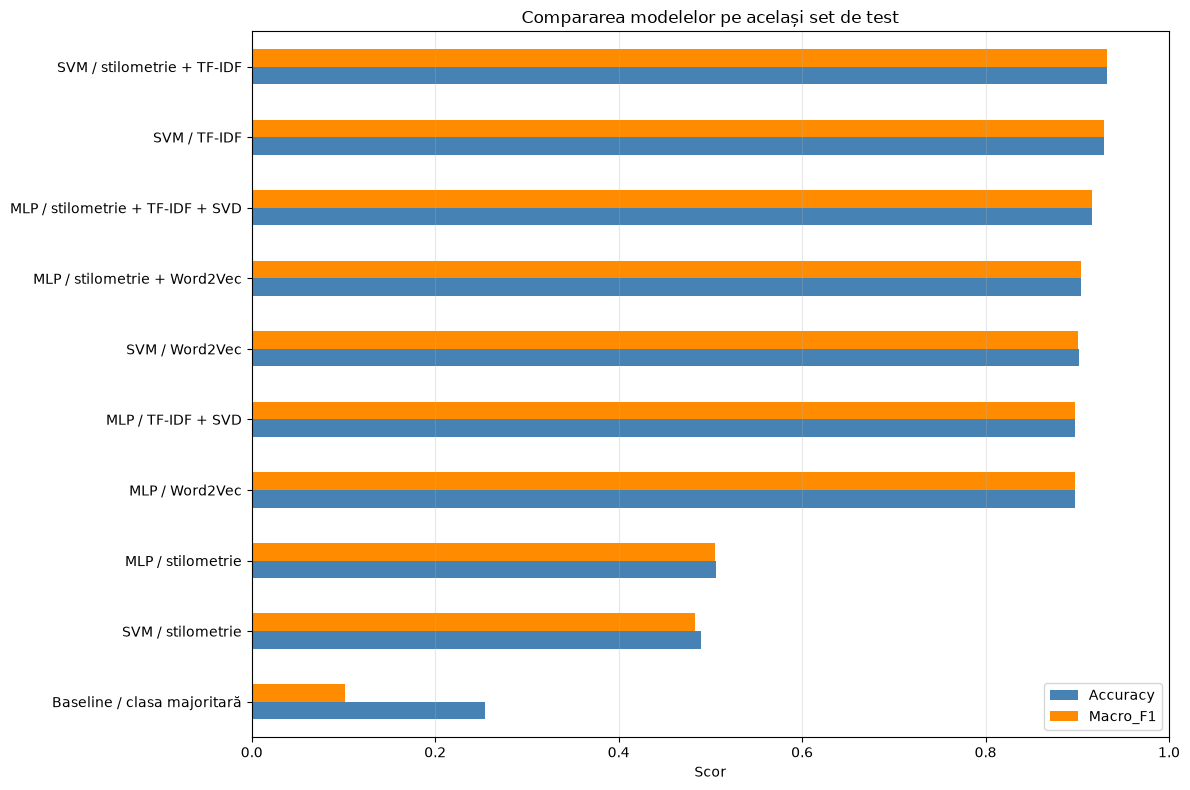

In [30]:
results_df = (
    pd.DataFrame(results)
    .sort_values("Macro_F1", ascending=False)
    .reset_index(drop=True)
)

print("\nCOMPARAȚIA MODELELOR")
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    "classification_results.csv",
    index=False,
)

plot_data = (
    results_df
    .set_index("Experiment")[["Accuracy", "Macro_F1"]]
    .sort_values("Macro_F1")
)

ax = plot_data.plot.barh(
    figsize=(12, 8),
    color=["steelblue", "darkorange"],
)

ax.set_xlim(0, 1)
ax.set_xlabel("Scor")
ax.set_ylabel("")
ax.set_title("Compararea modelelor pe același set de test")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("classification_comparison.png", dpi=300)
plt.show()

Category                          comp.graphics  rec.autos  sci.med  talk.politics.mideast
Experiment                                                                                
Baseline / clasa majoritară               0.000      0.000    0.405                  0.000
MLP / TF-IDF + SVD                        0.904      0.893    0.885                  0.909
MLP / Word2Vec                            0.928      0.880    0.891                  0.891
MLP / stilometrie                         0.398      0.489    0.500                  0.634
MLP / stilometrie + TF-IDF + SVD          0.927      0.899    0.910                  0.929
MLP / stilometrie + Word2Vec              0.918      0.880    0.900                  0.917
SVM / TF-IDF                              0.956      0.914    0.919                  0.928
SVM / Word2Vec                            0.925      0.874    0.897                  0.910
SVM / stilometrie                         0.395      0.485    0.461                  0.592

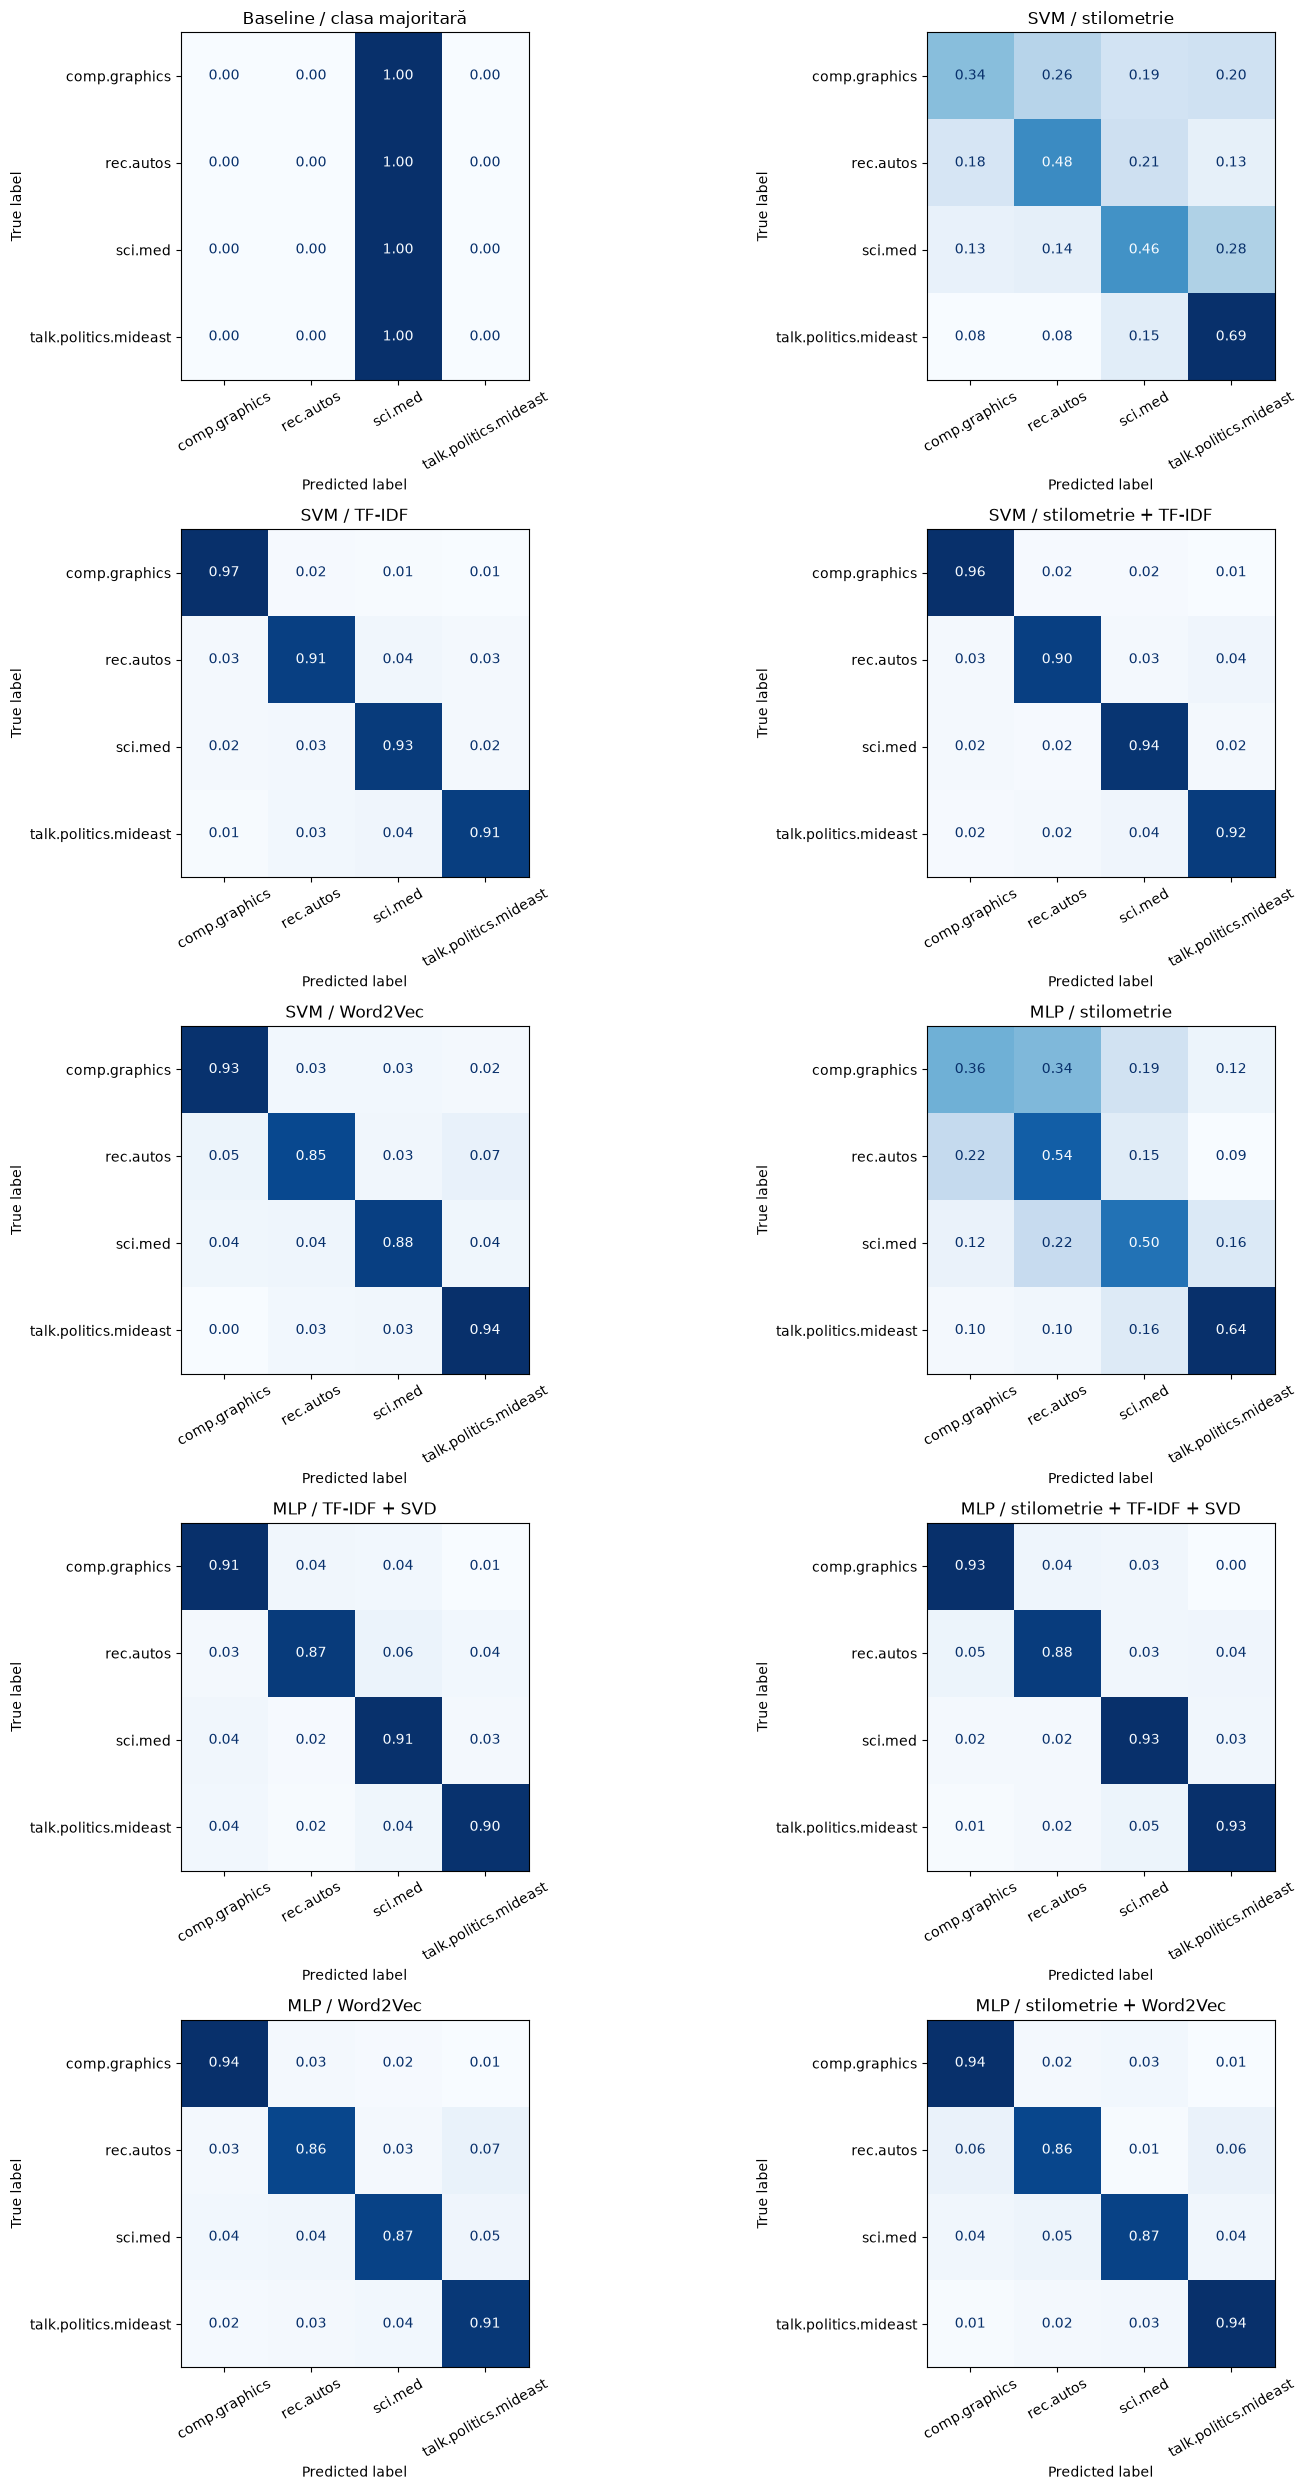

In [31]:
class_names = sorted(np.unique(y))

report_rows = []

for name, y_pred in predictions.items():
    report = classification_report(
        y_test,
        y_pred,
        labels=class_names,
        output_dict=True,
        zero_division=0,
    )

    for category in class_names:
        report_rows.append({
            "Experiment": name,
            "Category": category,
            **report[category],
        })

per_class_df = pd.DataFrame(report_rows)

print(
    per_class_df.pivot(
        index="Experiment",
        columns="Category",
        values="f1-score",
    ).round(3).to_string()
)

per_class_df.to_csv(
    "classification_per_class.csv",
    index=False,
)

ncols = 2
nrows = (len(predictions) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(16, 5 * nrows),
)

for ax, (name, y_pred) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=class_names,
        normalize="true",
        values_format=".2f",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )

    ax.set_title(name)
    ax.tick_params(axis="x", rotation=30)

for ax in list(axes.flat)[len(predictions):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("classification_confusion_matrices.png", dpi=200)
plt.show()